<div dir="rtl">

# POLYHAQ CV–DJ · مرحله ۲ — نوت‌بوک کامل تیم `polyhaq`

**چالش:** `PQO–2026–CV01` — الگوریتم Deutsch–Jozsa پیوسته‌متغیر
**تیم:** `polyhaq` · **گیت‌های آزادشده در مرحله ۱:** `S` و `P` (به‌علاوهٔ پایه‌های `I`, `R`, `X`)

این یک فایل، **همهٔ** تحویلی مرحله ۲ است: کد بهینه‌سازی، راستی‌آزمایی با ارزیاب رسمی،
نمودارها، و گزارش روش و نتایج. هیچ فایل کمکی لازم ندارد جز خودِ ماژول رسمی
`cv_dj_stage2_public_evaluator.py`. سلول آخر، `submission.json` را می‌نویسد.

---

### نتیجهٔ نهایی (ارزیاب رسمی، ۲۴ سید عمومی)

| کمیت | مقدار | حد |
|---|---|---|
| `S_worst` | **0.87732473** | نقطهٔ شروع رسمی: 0.83138 |
| `DJ score` | **87.7325 / 100** | — |
| `Stage-2` | **40.1732 / 60** | — |
| `min raw_trace` | 0.98633 | ≥ 0.98 |
| `max edge3` | 0.00129 | ≤ 0.02 |
| `max n̄` | 6.398 | ≤ 8.0 |
| `Σ|r|` | 0.39361 | ≤ 0.40 |

مدار تحویلی **هیچ گیت `V` ندارد** — دلیلش در بخش ۹.

---

### ترتیب اجرا

۱ · پیکربندی و محیط  ·  ۲ · صورت مسئله  ·  ۳ · موتور سریع (و باگی که پنهان کرده بود)
۴ · راستی‌آزمایی موتور سریع در برابر Strawberry Fields  ·  ۵ · نقطهٔ شروع و گلوگاه
۶ · مکانیزم: چرا مسئله به یک انتگرال تقلیل می‌یابد  ·  ۷ · ansatz و تابع هدف
۸ · بهینه‌سازی  ·  ۹ · حذف `V`  ·  ۱۰ · اعتبارسنجی و ارزیاب رسمی
۱۱ · ایمنی قید و انتخاب کاندیدا  ·  ۱۲ · نمودارها  ·  ۱۳ · چک‌لیست و نوشتن فایل تحویلی
۱۴ · گزارش روش و نتایج

</div>

<div dir="rtl">

## ۱ · پیکربندی و محیط

سه کلید زیر تعیین می‌کنند نوت‌بوک چقدر کار انجام دهد:

* `RUN_OPTIMISATION` — اجرای کامل بهینه‌سازی (چند ساعت). پیش‌فرض خاموش؛ پارامترهای
  تحویلی در همین فایل درج شده‌اند.
* `RUN_OFFICIAL` — اجرای ارزیاب رسمی روی ۲۴ سید (حدود ۵ تا ۸ دقیقه). پیش‌فرض روشن،
  چون **هر عددی که در گزارش می‌آید باید از ارزیاب رسمی آمده باشد، نه از موتور سریع ما.**
* `RUN_ABLATION` — مقایسهٔ نسخهٔ با `V` و بدون `V` با موتور سریع (حدود ۳۰ ثانیه).

</div>

In [ ]:
RUN_OPTIMISATION = False    # hours; the delivered parameters are embedded below
RUN_OFFICIAL     = True     # ~5-8 min; every reported number comes from here
RUN_ABLATION     = True     # ~30 s

import json, os, sys, time, textwrap
import numpy as np

t_notebook_start = time.time()

import cv_dj_stage2_public_evaluator as ev

print("python                :", sys.version.split()[0])
print("numpy                 :", np.__version__)
import scipy, strawberryfields as sf
print("scipy                 :", scipy.__version__)
print("strawberryfields      :", sf.__version__)
print()
env = ev.public_environment()
for k in ("modes", "n_bins", "bins", "N", "P", "hbar", "cutoff", "eta_total", "eta_stage", "phase_sigma",
          "gate_rel_sigma", "detector_sigma_x", "shots", "k_constant_min", "decision_delta",
          "oracle_smoothing_beta"):
    if k in env:
        print(f"{k:22}: {env[k]}")
print(f"{'public seeds':22}: {len(ev.PUBLIC_SEEDS)}  (fast subset: {len(ev.PUBLIC_SEEDS_FAST)})")

<div dir="rtl">

## ۲ · صورت مسئله، و آنچه واقعاً در اختیار ماست

ارزیاب این مدار را می‌سازد و ما فقط دو بلوک آبی‌رنگ را پر می‌کنیم:

</div>

```text
 |0>
  -> U_prep        [ 9 participant slots ]        <-- ours
  -> L1            loss channel,  eta_stage = 0.86^(1/3)
  -> R(dphi_1)     phase jitter
  -> R(+pi/2)      forward Fourier transform
  -> R(dphi_2)     phase jitter
  -> U_f           the oracle, called exactly once
  -> L2            loss channel
  -> R(dphi_3)     phase jitter
  -> R(-pi/2)      inverse Fourier transform
  -> L3            loss channel
  -> R(dphi_4)     phase jitter
  -> U_readout     [ 6 participant slots ]        <-- ours
  -> homodyne x,  8 shots,  decide CONSTANT if K >= 4
```

<div dir="rtl">

چهار قید پذیرش — نقض هر کدام یعنی **امتیاز صفر**، فارغ از `S_worst`:
`Σ|r| ≤ 0.40` · `n̄ ≤ 8` · `raw_trace ≥ 0.98` · `edge3 ≤ 0.02`

</div>

In [2]:
# Unlocked gates from Stage 1. Read from disk if present, otherwise use the value we submitted.
STAGE1_UNLOCKS = {"team": "polyhaq", "unlocked_gates": ["S", "P"]}
if os.path.exists("stage1_unlocks.json"):
    UNLOCKED = ev.load_unlocked_gates("stage1_unlocks.json")
else:
    with open("_stage1_unlocks_inline.json", "w") as f:
        json.dump(STAGE1_UNLOCKS, f)
    UNLOCKED = ev.load_unlocked_gates("_stage1_unlocks_inline.json")

DEV = list(ev.PUBLIC_SEEDS_FAST)     # 6 seeds  - optimisation only
ALL = list(ev.PUBLIC_SEEDS)          # 24 seeds - validation only

print("unlocked gates :", sorted(UNLOCKED))
print("dev seeds      :", DEV)
print("validation     :", ALL[:4], "...", ALL[-1])
print()
print("prep bounds    :", {g: ev.PREP_GATE_BOUNDS[g] for g in sorted(ev.PREP_GATE_BOUNDS)})
print("readout bounds :", {g: ev.READOUT_GATE_BOUNDS[g] for g in sorted(ev.READOUT_GATE_BOUNDS)})

unlocked gates : ['I', 'P', 'R', 'S', 'X']
dev seeds      : [2026090500, 2026090501, 2026090502, 2026090503, 2026090504, 2026090505]
validation     : [2026090500, 2026090501, 2026090502, 2026090503] ... 2026090523

prep bounds    : {'I': (0.0, 0.0), 'P': (-1.6, 1.6), 'R': (-3.141592653589793, 3.141592653589793), 'S': (-0.4, 0.4), 'V': (-0.09, 0.09), 'X': (-1.0, 1.0)}
readout bounds : {'I': (0.0, 0.0), 'P': (-1.3, 1.3), 'R': (-1.3, 1.3), 'S': (-0.4, 0.4), 'V': (-0.06, 0.06), 'X': (-0.75, 0.75)}


<div dir="rtl">

## ۳ · موتور سریع — و باگی که پنهان کرده بود

یک ارزیابی رسمی حدود ۱۹۰ بار ساختن برنامهٔ Strawberry Fields است، یعنی چند دقیقه.
ما فقط **انتشار حالت** را در numpy بازنویسی کردیم؛ ثابت‌ها، مدل اوراکل، قرعهٔ نویز و
قاعدهٔ امتیازدهی همگی از ماژول رسمی `import` می‌شوند. سه تسریع، هر سه دقیق:

۱. کانال اتلاف به‌صورت یک جمع برداری به‌جای ۴۸ ضرب ماتریسی کراوس.
۲. `p_win = tr(ρW) / tr(ρM)` با دو ماتریس ثابت ۴۸×۴۸ — چون `gaussian_filter1d` و
   قاعدهٔ ذوزنقه هر دو خطی‌اند، شبکهٔ ۱۴۰۱ نقطه‌ای یک بار در عملگر تا می‌شود.
۳. حالت `prep` و یکانیِ `readout` یک بار در هر سید ساخته و برای هر ۸ اوراکل استفاده می‌شوند.

**نتیجه:** ارزیابی ۲۴ سید از حدود ۷ دقیقه به حدود ۶ ثانیه.

### باگی که ارزش گزارش کردن دارد

نسخهٔ اول این موتور گیت‌ها را با `expm` از **مولد کوتاه‌شده** می‌ساخت. آن ماتریس در فضای
۴۸‌بعدی **دقیقاً یکانی** است، پس رد را حفظ می‌کند و همیشه `raw_trace = 1.000000` گزارش می‌شد.
اما Strawberry Fields چیز دیگری می‌کند: **عناصر ماتریسیِ کوتاه‌شدهٔ گیتِ بی‌نهایت‌بعدی** را
به کار می‌برد که یکانی **نیستند** — و همان ردِ ازدست‌رفته، دقیقاً قید `raw_trace ≥ 0.98` است.

کاندیدایی با `S_worst = 0.8978` را موتور ما «سالم» اعلام کرد و ارزیاب رسمی ردش کرد:
`min raw trace = 0.96973`. راه‌حل: صدا زدن مستقیم
`strawberryfields.backends.fockbackend.ops` برای هر ماتریس گیت — با همان تجزیه‌هایی که
خودِ SF انجام می‌دهد (`P` به `S`+`R`، و `X`/`Z` به `D`). پس از اصلاح، دو موتور روی
`raw_trace` تا `1.2e-15` و روی `success` تا `2.5e-04` توافق دارند.

**درس:** یک مدل جایگزین که از مرجع *فیزیکی‌تر* باشد، تقریبِ محافظه‌کارانه نیست.
همان ویژگی اضافه می‌تواند نسبت به قیدی که اعتبار را تعیین می‌کند کور باشد.

</div>

In [3]:
from scipy.ndimage import gaussian_filter1d
import strawberryfields.backends.fockbackend.ops as _sfops

C, HBAR = ev.CUTOFF, ev.HBAR
_a  = np.diag(np.sqrt(np.arange(1, C)), 1).astype(complex)
_ad = _a.conj().T
_nvec = np.arange(C, dtype=float)
_ID = np.eye(C, dtype=complex)

_gate_cache = {}


def gate(name, theta):
    """Exactly the matrices Strawberry Fields' Fock backend uses.

    These are the truncated matrix elements of the infinite-dimensional gate, which are
    NOT unitary inside the 48-dimensional space.  That is not a detail: the resulting loss
    of trace IS the acceptance constraint raw_trace >= 0.98.  Building the gates with
    expm() of a truncated generator instead gives an exactly unitary matrix, hides the
    trace loss, and produces submissions the official evaluator rejects.
    """
    if name == "I" or theta == 0.0:
        return _ID
    key = (name, float(theta))
    U = _gate_cache.get(key)
    if U is None:
        t = float(theta)
        if name == "R":
            U = np.asarray(_sfops.phase(t, C))
        elif name == "S":
            U = np.asarray(_sfops.squeezing(t, 0.0, C))
        elif name == "X":                          # Xgate -> Dgate(x / sqrt(2 hbar), 0)
            U = np.asarray(_sfops.displacement(t / np.sqrt(2.0 * HBAR), 0.0, C))
        elif name == "Z":                          # Zgate -> Dgate(p / sqrt(2 hbar), pi/2)
            U = np.asarray(_sfops.displacement(t / np.sqrt(2.0 * HBAR), np.pi / 2, C))
        elif name == "P":                          # Pgate -> Sgate(r, phi) then Rgate(th)
            h  = t / 2.0
            r  = np.arccosh(np.sqrt(1.0 + h * h))
            th = np.arctan(h)
            ph = -np.pi / 2.0 * np.sign(h) - th
            U = np.asarray(_sfops.phase(th, C)) @ np.asarray(_sfops.squeezing(r, ph, C))
        elif name == "V":
            U = np.asarray(_sfops.cubicPhase(t, HBAR, C))
        else:
            raise ValueError(name)
        U = U.astype(complex)
        if len(_gate_cache) > 3000:                # bounded: an unbounded cache OOM-killed a run
            _gate_cache.clear()
        _gate_cache[key] = U
    return U


# ---- loss channel -----------------------------------------------------------------
_KR = [np.asarray(K, dtype=complex)
       for K in _sfops.lossChannel(ev.ETA_STAGE, C)
       if np.abs(np.asarray(K)).max() > 1e-15]


def loss(rho):
    return sum(K @ rho @ K.conj().T for K in _KR)


# ---- decision window folded into two fixed 48x48 matrices -------------------------
_B      = np.real(ev.fock_x_basis(C))
_DX     = float(ev.X_GRID[1] - ev.X_GRID[0])
_SIGPIX = ev.DETECTOR_SIGMA_X / _DX


def _trapz_weights(mask):
    w = np.zeros_like(ev.X_GRID)
    idx = np.where(mask)[0]
    xs = ev.X_GRID[idx]
    w[idx[0]]  += (xs[1] - xs[0]) / 2.0
    w[idx[-1]] += (xs[-1] - xs[-2]) / 2.0
    for a in range(1, len(idx) - 1):
        w[idx[a]] += (xs[a + 1] - xs[a - 1]) / 2.0
    return w


_MASK  = (ev.X_GRID >= -ev.WINDOW_DELTA) & (ev.X_GRID <= +ev.WINDOW_DELTA)
_w_win = gaussian_filter1d(_trapz_weights(_MASK), sigma=_SIGPIX, mode="nearest")
_w_all = gaussian_filter1d(_trapz_weights(np.ones_like(ev.X_GRID, dtype=bool)),
                           sigma=_SIGPIX, mode="nearest")
_W = np.einsum("nk,k,mk->nm", _B, _w_win, _B, optimize=True)
_M = np.einsum("nk,k,mk->nm", _B, _w_all, _B, optimize=True)
_W_clean = np.einsum("nk,k,mk->nm", _B, _trapz_weights(_MASK), _B, optimize=True)


def _pwin(r, clean=False):
    Wm = _W_clean if clean else _W
    Mm = np.eye(C) if clean else _M
    return float(np.real(np.sum(r * Wm.T)) / np.real(np.sum(r * Mm.T)))


def _prep_state(prep, pz):
    psi = np.zeros(C, dtype=complex)
    psi[0] = 1.0
    for i, (g, th) in enumerate(prep):
        if pz is not None:
            th = ev._perturb_participant_theta(th, pz[i])
        if g != "I" and th != 0.0:
            psi = gate(g, th) @ psi
    return psi


def _readout_U(readout, rz):
    U = _ID
    for i, (g, th) in enumerate(readout):
        if rz is not None:
            th = ev._perturb_participant_theta(th, rz[i])
        if g != "I" and th != 0.0:
            U = gate(g, th) @ U
    return U


_orc_cache = {}


def _oracle_U(oracle_id, seed):
    key = (oracle_id, seed)
    U = _orc_cache.get(key)
    if U is None:
        coeff = ev.oracle_coefficients(oracle_id).copy()
        if seed is not None:
            coeff[1:] = ev._perturb_oracle_coefficients(
                coeff[1:], ev.sample_noise_draw(seed)["oracle_z"])
        U = _ID
        a1, a2, a3 = coeff[1], coeff[2], coeff[3]
        if abs(a1) > 1e-12:
            U = gate("Z", a1 * HBAR) @ U
        if abs(a2) > 1e-12:
            U = gate("P", 2.0 * a2 * HBAR) @ U
        if abs(a3) > 1e-12:
            U = gate("V", 3.0 * a3 * HBAR) @ U
        _orc_cache[key] = U
    return U


def run(prep, readout, oracle_id, seed=None, noisy=True):
    """One shot-free run: returns p_win, success, raw_trace, nbar, edge3."""
    if noisy:
        d = ev.sample_noise_draw(seed)
        dphi = ev.PHASE_SIGMA * d["phase_z"]
        pz, rz = d["prep_z"], d["readout_z"]
    else:
        dphi = np.zeros(4)
        pz = rz = None

    psi = _prep_state(prep, pz)
    rho = np.outer(psi, psi.conj())
    if noisy:
        rho = loss(rho)
    U = gate("R", dphi[0] + np.pi / 2.0 + dphi[1]); rho = U @ rho @ U.conj().T
    Uo = _oracle_U(oracle_id, seed if noisy else None); rho = Uo @ rho @ Uo.conj().T
    if noisy:
        rho = loss(rho)
    U = gate("R", dphi[2] - np.pi / 2.0); rho = U @ rho @ U.conj().T
    if noisy:
        rho = loss(rho)
    U = gate("R", dphi[3]); rho = U @ rho @ U.conj().T
    Ur = _readout_U(readout, rz); rho = Ur @ rho @ Ur.conj().T

    raw_trace = float(np.real(np.trace(rho)))
    r = rho / raw_trace
    pn = np.real(np.diag(r))
    pw = _pwin(r, clean=not noisy)
    return {"pwin": pw,
            "success": ev.exact_shot_success(pw, ev.promise_label(oracle_id)),
            "raw_trace": raw_trace,
            "nbar": float(np.sum(_nvec * pn)),
            "edge3": float(np.sum(pn[-3:]))}


def evaluate(prep, readout, seeds, oracles=ev.PROMISED_ORACLES, collect=False):
    """Multi-seed evaluation; prep state and readout unitary are built once per seed."""
    R, Mn = len(seeds), len(oracles)
    succ = np.empty((R, Mn))
    trc  = np.empty((R, Mn))
    min_tr, max_e3, max_nb = 1.0, 0.0, 0.0
    for i, sd in enumerate(seeds):
        d = ev.sample_noise_draw(sd)
        dphi = ev.PHASE_SIGMA * d["phase_z"]
        psi = _prep_state(prep, d["prep_z"])
        base = loss(np.outer(psi, psi.conj()))
        U1 = gate("R", dphi[0] + np.pi / 2.0 + dphi[1]); base = U1 @ base @ U1.conj().T
        U2 = gate("R", dphi[2] - np.pi / 2.0)
        U3 = gate("R", dphi[3])
        post = _readout_U(readout, d["readout_z"]) @ U3
        for j, z in enumerate(oracles):
            Uo = _oracle_U(z, sd)
            rho = Uo @ base @ Uo.conj().T
            rho = loss(rho)
            rho = U2 @ rho @ U2.conj().T
            rho = loss(rho)
            rho = post @ rho @ post.conj().T
            tr = float(np.real(np.trace(rho)))
            r = rho / tr
            pn = np.real(np.diag(r))
            succ[i, j] = ev.exact_shot_success(_pwin(r), ev.promise_label(z))
            trc[i, j]  = tr
            min_tr = min(min_tr, tr)
            max_e3 = max(max_e3, float(np.sum(pn[-3:])))
            max_nb = max(max_nb, float(np.sum(_nvec * pn)))
    means = succ.mean(axis=0)
    j = int(np.argmin(means))
    sq = sum(abs(t) for g, t in list(prep) + list(readout) if g == "S")
    out = {"worst": float(means[j]), "worst_oracle": oracles[j],
           "means": {z: float(means[k]) for k, z in enumerate(oracles)},
           "min_trace": min_tr, "max_edge3": max_e3, "max_nbar": max_nb,
           "squeeze": sq,
           "safe": (min_tr >= ev.TRACE_LIMIT and max_e3 <= ev.EDGE3_LIMIT
                    and max_nb <= ev.NBAR_LIMIT and sq <= ev.SQUEEZE_BUDGET + 1e-12)}
    if collect:
        out["success_matrix"] = succ
        out["trace_matrix"] = trc
    return out


print("fast engine ready — gates taken from strawberryfields.backends.fockbackend.ops")

fast engine ready — gates taken from strawberryfields.backends.fockbackend.ops


<div dir="rtl">

## ۴ · راستی‌آزمایی موتور سریع در برابر Strawberry Fields

**اگر این سلول خطا بدهد، هیچ عددی در ادامهٔ نوت‌بوک قابل اعتماد نیست.**
مقایسه روی نقطهٔ شروع رسمی و روی مدار تحویلی، هر دو، انجام می‌شود.

</div>

In [4]:
def as_pairs(sub):
    return ([(d["gate"], d["theta"]) for d in sub["prep"]],
            [(d["gate"], d["theta"]) for d in sub["readout"]])


prep0, read0 = as_pairs(ev.STARTER_SUBMISSION)

t0 = time.time()
worst_succ = worst_tr = 0.0
for sd in ev.PUBLIC_SEEDS[:2]:
    for z in ev.PROMISED_ORACLES:
        a = ev.run_submission(ev.STARTER_SUBMISSION, z, seed=sd)
        b = run(prep0, read0, z, seed=sd)
        worst_succ = max(worst_succ, abs(a["success"] - b["success"]))
        worst_tr   = max(worst_tr,   abs(a["raw_trace"] - b["raw_trace"]))
print(f"SF vs fast, 16 comparisons  |Δsuccess|max = {worst_succ:.2e}   "
      f"|Δraw_trace|max = {worst_tr:.2e}   [{time.time()-t0:.1f}s]")

assert worst_succ < 1e-3, "fast engine disagrees with Strawberry Fields on success"
assert worst_tr   < 1e-9, "fast engine disagrees with Strawberry Fields on raw_trace"
print("OK — the fast engine reproduces the official evaluator, raw_trace included.")

SF vs fast, 16 comparisons  |Δsuccess|max = 2.05e-04   |Δraw_trace|max = 1.22e-15   [4.7s]
OK — the fast engine reproduces the official evaluator, raw_trace included.


<div dir="rtl">

## ۵ · نقطهٔ شروع رسمی، و جایی که گلوگاه است

جدول زیر تمام راهبرد را تعیین می‌کند: اوراکل‌های متوازن از قبل بالای ۹۹ درصدند و
**تمام گلوگاه، جفت `constant` است**. ضمناً هر شش اسلات `readout` در نقطهٔ شروع روی `I`
مانده‌اند — یعنی ۴۰ درصد از عمق قابل‌کنترل بلااستفاده است.

</div>

In [5]:
t0 = time.time()
res0 = evaluate(prep0, read0, ALL)
print(f"starter, 24 public seeds:  S_worst = {res0['worst']:.6f}  ({res0['worst_oracle']})"
      f"   [{time.time()-t0:.1f}s with the fast engine]\n")
print(f"{'oracle':>8}  {'promise':<9} {'mean success':>13}")
for z, v in res0["means"].items():
    print(f"{z:>8}  {ev.promise_label(z):<9} {v:>13.6f}")
print("\nstarter readout slots:", [(d['gate'], d['theta']) for d in ev.STARTER_SUBMISSION['readout']])

starter, 24 public seeds:  S_worst = 0.836201  (0000)   [6.7s with the fast engine]

  oracle  promise    mean success
    0000  constant       0.836201
    1111  constant       0.836201
    0011  balanced       0.998421
    1100  balanced       0.998380
    0110  balanced       0.993281
    1001  balanced       0.993452
    0101  balanced       0.886675
    1010  balanced       0.887069

starter readout slots: [('I', 0.0), ('I', 0.0), ('I', 0.0), ('I', 0.0), ('I', 0.0), ('I', 0.0)]


<div dir="rtl">

## ۶ · مکانیزم — چرا کل مرحله ۲ به یک انتگرال تقلیل می‌یابد

برای یک تابع `constant`، فاز اوراکل `φ(x) = π·f` به `x` بستگی ندارد، پس یک عدد مختلط
است، نه یک عملگر. عدد با هر عملگری جابه‌جا می‌شود، بنابراین:

$$\mathcal{F}^{-1}\,e^{i\varphi}\,\mathcal{F} = e^{i\varphi}\,\mathbb{1}$$

فاز سراسری در چگالی حذف می‌شود، پس حالتی که به آشکارساز می‌رسد **همان حالت `prep`** است:

$$p_{\rm win}^{\rm const} \;=\; \int_{|x|\le\Delta} \bigl|\psi_{\rm prep}(x)\bigr|^{2}\,dx,
\qquad \Delta=\frac{\pi}{2P}=\frac{\pi}{6}\simeq 0.5236$$

یعنی تمام مسئله این است: توزیع مکانیِ حالت `prep` را تا حد ممکن داخل پنجره‌ای به
نیم‌پهنای `π/6` جمع کن — بدون اینکه بازترکیبِ اوراکل‌های متوازن به همان پنجره نشت کند.

سلول زیر همین را عددی تأیید می‌کند.

</div>

In [6]:
DELIVERED = {
    "schema_version": 1,
    "team": "polyhaq",
    "prep": [{"gate": "S", "theta":  0.36113200},
             {"gate": "R", "theta":  0.57924846},
             {"gate": "P", "theta": -1.05130882},
             {"gate": "I", "theta":  0.0},
             {"gate": "R", "theta": -1.13949711},
             {"gate": "P", "theta":  0.18265712},
             {"gate": "I", "theta":  0.0},
             {"gate": "R", "theta":  0.80194097},
             {"gate": "X", "theta": -0.05938300}],
    "readout": [{"gate": "R", "theta": -0.05715186},
                {"gate": "P", "theta":  0.04701168},
                {"gate": "I", "theta":  0.0},
                {"gate": "R", "theta": -0.08839568},
                {"gate": "P", "theta": -0.06597984},
                {"gate": "S", "theta":  0.03247688}],
}
PREP, READ = as_pairs(DELIVERED)

X, D = ev.X_GRID, ev.WINDOW_DELTA
Bx = np.real(ev.fock_x_basis(ev.CUTOFF))


def pdf_of(rho):
    r = rho / np.real(np.trace(rho))
    p = np.real(np.einsum("nk,nm,mk->k", Bx, r, Bx, optimize=True))
    p = np.maximum(p, 0.0)
    return p / np.trapezoid(p, X)


def window_mass(p):
    m = np.abs(X) <= D
    return float(np.trapezoid(p[m], X[m]))


psi_prep = _prep_state(PREP, None)
rho_prep = np.outer(psi_prep, psi_prep.conj())
pdf_prep = pdf_of(rho_prep)

# the claim: for a constant oracle the detector sees exactly the prep state
def noiseless_out(z):
    rho = np.outer(psi_prep, psi_prep.conj())
    U = gate("R", np.pi / 2.0);  rho = U @ rho @ U.conj().T
    Uo = _oracle_U(z, None);     rho = Uo @ rho @ Uo.conj().T
    U = gate("R", -np.pi / 2.0); rho = U @ rho @ U.conj().T
    Ur = _readout_U(READ, None); rho = Ur @ rho @ Ur.conj().T
    return pdf_of(rho)


pdf_const = noiseless_out("0000")
pdf_bal   = noiseless_out("0101")

# reference: prep state pushed through the readout only, no oracle at all
rho_ro = _readout_U(READ, None) @ rho_prep @ _readout_U(READ, None).conj().T
pdf_no_oracle = pdf_of(rho_ro)

print(f"p_win  constant oracle 0000, noiseless   = {window_mass(pdf_const):.6f}")
print(f"p_win  prep state through readout only   = {window_mass(pdf_no_oracle):.6f}")
print(f"max |pdf difference|                     = {np.abs(pdf_const-pdf_no_oracle).max():.2e}"
      "   <-- the two Fourier transforms cancelled\n")
print(f"p_win  balanced oracle 0101, noiseless   = {window_mass(pdf_bal):.6f}")

# the pre-oracle profile, and the four bin amplitudes the oracle stamps +/- on
U = gate("R", np.pi / 2.0)
pdf_pre = pdf_of(U @ rho_prep @ U.conj().T)
edges = np.linspace(-ev.P, ev.P, ev.N + 1)
c = [float(np.trapezoid(np.sqrt(pdf_pre[(X >= edges[i]) & (X <= edges[i+1])]),
                        X[(X >= edges[i]) & (X <= edges[i+1])])) for i in range(ev.N)]
print(f"\nbin amplitudes c_j = {np.round(c, 4)}")
print("the four bins do NOT carry equal weight, so the alternating +/- pattern of 0101/1010")
print("cancels only partially — which is exactly why those are the hardest balanced oracles.")

p_win  constant oracle 0000, noiseless   = 0.795868
p_win  prep state through readout only   = 0.795868
max |pdf difference|                     = 0.00e+00   <-- the two Fourier transforms cancelled

p_win  balanced oracle 0101, noiseless   = 0.247740

bin amplitudes c_j = [0.4842 0.5915 0.5915 0.4842]
the four bins do NOT carry equal weight, so the alternating +/- pattern of 0101/1010
cancels only partially — which is exactly why those are the hardest balanced oracles.


<div dir="rtl">

## ۷ · `ansatz` و تابع هدف

**`ansatz`.** شکل لایه‌ای نقطهٔ شروع برای `prep` حفظ می‌شود و هر شش اسلات `readout` پر می‌شود.
جست‌وجو با `V` در سه اسلات انجام شد (بازهٔ مجازش تنگ است) و در بخش ۹ نشان می‌دهیم که
صفر کردن همان سه پارامتر نتیجه را **بهتر** می‌کند.

**قید فشردگی، جریمه نمی‌شود — تصویر می‌شود.** به‌جای اضافه کردن یک جملهٔ جریمه،
پارامترهای `S` بازمقیاس می‌شوند تا `Σ|r| ≤ 0.40` **ذاتاً** برقرار باشد. بهینه‌ساز هیچ‌وقت
وقتش را روی نقاط ناموجه تلف نمی‌کند.

**`softmin`.** امتیاز را بدترین اوراکل تعیین می‌کند، پس تابع هدف یک `minimax` است. اما
`min` خام در هر لحظه فقط از یک اوراکل جهت می‌گیرد و وقتی بدترین عوض می‌شود جهت جستجو
ناپیوسته می‌پرد. `softmin` چشم‌انداز را هموار می‌کند و خطایش نسبت به `min` حداکثر
`ln(8)/β` است — در `β = 30` حدود `0.069` و در `β = 80` حدود `0.026`. مرحلهٔ آخر روی
`min` **دقیق** اجرا می‌شود، پس عدد نهایی هیچ سوگیری‌ای از این تقریب ندارد.

**جریمه‌ها هدفشان مقادیری کاملاً درون حد مجاز است**، نه روی خودِ حد. دلیلش در بخش ۱۱.

</div>

In [7]:
PREP_NAMES = ["S", "R", "P", "V", "R", "P", "V", "R", "X"]
READ_NAMES = ["R", "P", "V", "R", "P", "S"]

LO = np.array([ev.PREP_GATE_BOUNDS[g][0] for g in PREP_NAMES]
              + [ev.READOUT_GATE_BOUNDS[g][0] for g in READ_NAMES])
HI = np.array([ev.PREP_GATE_BOUNDS[g][1] for g in PREP_NAMES]
              + [ev.READOUT_GATE_BOUNDS[g][1] for g in READ_NAMES])
SIDX = [i for i, g in enumerate(PREP_NAMES + READ_NAMES) if g == "S"]

NBAR_TARGET  = 7.60      # hard limit 8.00
EDGE3_TARGET = 0.015     # hard limit 0.02
TRACE_TARGET = 0.9850    # hard limit 0.98


def clean(x):
    """Clip to the published bounds, then PROJECT onto the squeezing budget."""
    x = np.clip(np.asarray(x, float), LO, HI)
    s = sum(abs(x[i]) for i in SIDX)
    if s > ev.SQUEEZE_BUDGET:
        for i in SIDX:
            x[i] *= ev.SQUEEZE_BUDGET / s * (1 - 1e-9)
    return x


def build(x):
    x = clean(x)
    return list(zip(PREP_NAMES, x[:9])), list(zip(READ_NAMES, x[9:]))


def softmin(v, beta):
    v = np.asarray(v, float)
    return float(-(1.0 / beta) * np.log(np.exp(-beta * (v - v.min())).sum()) + v.min())


def objective(x, seeds, beta=None):
    prep, read = build(x)
    r = evaluate(prep, read, seeds)
    vals = list(r["means"].values())
    sc = min(vals) if beta is None else softmin(vals, beta)
    pen = (2.0   * max(0.0, r["max_nbar"]  - NBAR_TARGET)
           + 100.0 * max(0.0, r["max_edge3"] - EDGE3_TARGET)
           + 400.0 * max(0.0, TRACE_TARGET  - r["min_trace"]))
    return -sc + pen


STARTER_X = np.array([d["theta"] for d in ev.STARTER_SUBMISSION["prep"]] + [0.0] * 6)
print("ansatz  prep   :", PREP_NAMES)
print("ansatz  readout:", READ_NAMES)
print("softmin error bound ln(8)/beta :", f"beta=30 -> {np.log(8)/30:.4f}",
      f"| beta=80 -> {np.log(8)/80:.4f}")

ansatz  prep   : ['S', 'R', 'P', 'V', 'R', 'P', 'V', 'R', 'X']
ansatz  readout: ['R', 'P', 'V', 'R', 'P', 'S']
softmin error bound ln(8)/beta : beta=30 -> 0.0693 | beta=80 -> 0.0260


<div dir="rtl">

## ۸ · بهینه‌سازی

`Nelder–Mead` تطبیقی روی **۶ سید توسعه**، پنج دور، با زمان‌بندی
`β = 30 → min دقیق → β = 80 → min دقیق → min دقیق`. هر دور از بهترین نقطهٔ جاری با یک
تکان تصادفی کوچک بازشروع می‌شود. گرادیان در دسترس نیست، چون تابع هدف شامل یک قاعدهٔ
تصمیم گسسته و یک شبیه‌سازی نویزدار است.

بهترین نقطه در **هر بهبود** روی دیسک ذخیره می‌شود؛ یک اجرای قبلی به‌خاطر کمبود حافظه
کشته شده بود و از دست رفت.

با `RUN_OPTIMISATION = False` این سلول فقط پارامترهای تحویلی را بارگذاری می‌کند.

</div>

In [8]:
HISTORY = []


def tracked(x, seeds, beta, best):
    f = objective(x, seeds, beta)
    r = evaluate(*build(x), seeds)
    HISTORY.append({"sworst": r["worst"], "trace": r["min_trace"], "nbar": r["max_nbar"],
                    "feasible": bool(r["safe"])})
    if f < best["f"]:
        best["f"], best["x"] = f, clean(x)
        np.save("best.npy", best["x"])
    return f


if RUN_OPTIMISATION:
    from scipy.optimize import minimize
    t0 = time.time()
    best = {"x": clean(STARTER_X), "f": objective(STARTER_X, DEV, 30.0)}
    np.save("best.npy", best["x"])
    rng = np.random.default_rng(7)
    for rnd, (beta, mf) in enumerate([(30.0, 360), (None, 420), (80.0, 360),
                                      (None, 420), (None, 420)]):
        x = best["x"] if rnd == 0 else clean(best["x"] + rng.normal(0, 0.03 * (HI - LO)))
        best["f"] = objective(best["x"], DEV, beta)
        minimize(tracked, x, args=(DEV, beta, best), method="Nelder-Mead",
                 options={"maxfev": mf, "xatol": 1e-4, "fatol": 1e-7, "adaptive": True})
        r = evaluate(*build(best["x"]), DEV)
        print(f"  round {rnd}  beta={str(beta):<5} S_worst(6 seeds)={r['worst']:.6f} "
              f"trace={r['min_trace']:.5f}  [{time.time()-t0:.0f}s]", flush=True)
    BEST_X = best["x"]
    json.dump(HISTORY, open("convergence_history.json", "w"))
    prep_opt, read_opt = build(BEST_X)
    SUBMISSION = {"schema_version": 1, "team": "polyhaq",
                  "prep":    [{"gate": g, "theta": round(float(t), 8)} for g, t in prep_opt],
                  "readout": [{"gate": g, "theta": round(float(t), 8)} for g, t in read_opt]}
else:
    SUBMISSION = json.loads(json.dumps(DELIVERED))
    print("RUN_OPTIMISATION = False — using the delivered parameters embedded in this notebook.")

PREP, READ = as_pairs(SUBMISSION)
print()
for lab, block in (("prep", SUBMISSION["prep"]), ("readout", SUBMISSION["readout"])):
    print(f"{lab:>8}:", "  ".join(f"{d['gate']}({d['theta']:+.6f})" for d in block))

RUN_OPTIMISATION = False — using the delivered parameters embedded in this notebook.



    prep: S(+0.361132)  R(+0.579248)  P(-1.051309)  I(+0.000000)  R(-1.139497)  P(+0.182657)  I(+0.000000)  R(+0.801941)  X(-0.059383)
 readout: R(-0.057152)  P(+0.047012)  I(+0.000000)  R(-0.088396)  P(-0.065980)  S(+0.032477)


<div dir="rtl">

## ۹ · حذف `V` — چرا صفر کردنش امتیاز را بالا برد

`V` تنها گیت غیرگاوسی است و بازهٔ مجازش تنگ (`|γ| ≤ 0.09` در `prep` و `0.06` در `readout`).
مقادیری که بهینه‌ساز پیدا کرد در بازهٔ `0.0013` تا `0.0143` بودند — سود فیزیکی‌شان ناچیز،
اما همچنان نویز کالیبراسیون گیت را حمل می‌کردند:

```
θ' = θ + 0.003 · max(|θ|, 0.02) · z
```

و این جمله برای `θ = 0` **دقیقاً صفر** است. پس صفر کردن اسلات، آن را به یک `I` بی‌نویز
تبدیل می‌کند.

سود دوم، خارج از مرحله ۲ است: `V` در هیچ‌کدام از ده جعبهٔ مرحله ۱ شناسایی نشده بود، پس
آزادسازی‌اش نیازمند `Rescue Token` با هزینهٔ ۳ امتیاز خام بود. با حذف `V`، آن توکن خرج نشد.

</div>

In [9]:
WITH_V = {
    "schema_version": 1, "team": "polyhaq",
    "prep": [{"gate": "S", "theta":  0.36113200}, {"gate": "R", "theta":  0.57924846},
             {"gate": "P", "theta": -1.05130882}, {"gate": "V", "theta": -0.01425610},
             {"gate": "R", "theta": -1.13949711}, {"gate": "P", "theta":  0.18265712},
             {"gate": "V", "theta":  0.00291632}, {"gate": "R", "theta":  0.80194097},
             {"gate": "X", "theta": -0.05938300}],
    "readout": [{"gate": "R", "theta": -0.05715186}, {"gate": "P", "theta":  0.04701168},
                {"gate": "V", "theta":  0.00127904}, {"gate": "R", "theta": -0.08839568},
                {"gate": "P", "theta": -0.06597984}, {"gate": "S", "theta":  0.03247688}],
}

if RUN_ABLATION:
    t0 = time.time()
    r_with = evaluate(*as_pairs(WITH_V), ALL)
    r_wo   = evaluate(PREP, READ, ALL)
    pts = lambda s: 60.0 * float(np.clip((s - ev.STARTER_REFERENCE_WORST)
                                         / (ev.STRETCH_TARGET - ev.STARTER_REFERENCE_WORST), 0, 1))
    print(f"{'variant':<24}{'S_worst':>11}{'min trace':>12}{'unlocks':>12}{'Stage-2 pts':>13}")
    print(f"{'with V (3 slots)':<24}{r_with['worst']:>11.6f}{r_with['min_trace']:>12.5f}"
          f"{'S, P, V':>12}{pts(r_with['worst']):>13.2f}")
    print(f"{'V set to exactly 0':<24}{r_wo['worst']:>11.6f}{r_wo['min_trace']:>12.5f}"
          f"{'S, P':>12}{pts(r_wo['worst']):>13.2f}")
    print(f"\ngain from dropping V : {r_wo['worst']-r_with['worst']:+.6f} in S_worst"
          f"  ({pts(r_wo['worst'])-pts(r_with['worst']):+.2f} Stage-2 points)"
          f"  [fast engine, {time.time()-t0:.0f}s]")
    print("plus 3 raw Stage-1 points: the Rescue Token for the V unlock was never spent.")
else:
    print("RUN_ABLATION = False")

variant                     S_worst   min trace     unlocks  Stage-2 pts
with V (3 slots)           0.876440     0.98635     S, P, V        39.40
V set to exactly 0         0.877325     0.98633        S, P        40.17

gain from dropping V : +0.000884 in S_worst  (+0.77 Stage-2 points)  [fast engine, 5s]
plus 3 raw Stage-1 points: the Rescue Token for the V unlock was never spent.


<div dir="rtl">

## ۱۰ · اعتبارسنجی و ارزیاب رسمی

**بیش‌برازش.** توسعه روی ۶ سید انجام شد؛ اعتبارسنجی روی هر ۲۴ سید که بهینه‌ساز هرگز
ندیده است. فاصلهٔ این دو، برآورد صادقانهٔ سهمِ برازشِ سیدی است. رتبه‌بندی رسمی روی
**۲۰۰ سید خصوصی** انجام می‌شود که در هیچ‌کدام از این دو مجموعه نیست — پس عددی که انتظار
داریم بازتولید شود، عددِ ۲۴ سید است، نه عددِ ۶ سید.

</div>

In [10]:
r_dev = evaluate(PREP, READ, DEV)
r_all = evaluate(PREP, READ, ALL, collect=True)
print(f"S_worst on  6 development seeds : {r_dev['worst']:.6f}")
print(f"S_worst on 24 validation seeds  : {r_all['worst']:.6f}")
print(f"overfitting gap                 : {r_dev['worst']-r_all['worst']:+.6f}")

S_worst on  6 development seeds : 0.893586
S_worst on 24 validation seeds  : 0.877325
overfitting gap                 : +0.016261


In [11]:
if RUN_OFFICIAL:
    t0 = time.time()
    OFFICIAL = ev.evaluate_submission(SUBMISSION, seeds=ALL, unlocked_gates=UNLOCKED,
                                      include_clean=True, progress=True)
    print(f"\n[official evaluator, {time.time()-t0:.0f}s]\n")
    ev.print_result(OFFICIAL)
    print(f"\nDJ score       : {ev.dj_score(OFFICIAL):.4f}/100")
    print(f"Stage-2 points : {ev.stage2_points(OFFICIAL):.4f}/60")
else:
    OFFICIAL = None
    print("RUN_OFFICIAL = False — no officially verified numbers produced.")

development seeds: 4/24


development seeds: 8/24


development seeds: 12/24


development seeds: 16/24


development seeds: 20/24


development seeds: 24/24



[official evaluator, 17s]

CV-DJ STAGE-2 PUBLIC DEVELOPMENT RESULT
development safe : True
S_worst          : 0.87732473
worst oracle     : 1111
mean success     : 0.94104833
clean worst      : 0.88031176
min raw trace    : 0.98633491
max edge3        : 0.00128887
max nbar         : 6.39806871
total squeezing  : 0.39360888
public seeds     : 24
------------------------------------------------------------------------------
DJ Score         : 87.7325/100
Stage-2 estimate : 40.1732/60
PUBLIC DEVELOPMENT ONLY — official ranking uses private common seeds.

DJ score       : 87.7325/100
Stage-2 points : 40.1732/60


In [12]:
if OFFICIAL is not None:
    print(f"{'oracle':>8}  {'promise':<9} {'mean success':>13} {'q10':>10} "
          f"{'mean p_win':>11} {'clean':>10}")
    for r in OFFICIAL["rows"]:
        print(f"{r['oracle']:>8}  {r['promise']:<9} {r['mean_success']:>13.6f} "
              f"{r['q10_success']:>10.6f} {r['mean_pwin']:>11.5f} "
              f"{r.get('clean_success', float('nan')):>10.6f}")
    print("\nThe constant pair and the 0101/1010 pair have been driven to nearly the same")
    print("value — with a worst-case objective, that is what an optimum looks like.")

  oracle  promise    mean success        q10  mean p_win      clean


    0000  constant       0.877325   0.829919     0.63902   0.988614
    1111  constant       0.877325   0.829919     0.63902   0.988614
    0011  balanced       0.997139   0.996846     0.08572   0.998924
    1100  balanced       0.998629   0.998474     0.07040   0.999718
    0110  balanced       0.994342   0.993340     0.10315   0.995327
    1001  balanced       0.994344   0.993723     0.10317   0.995285
    0101  balanced       0.895472   0.892758     0.24312   0.889290
    1010  balanced       0.893812   0.889836     0.24437   0.880312

The constant pair and the 0101/1010 pair have been driven to nearly the same
value — with a worst-case objective, that is what an optimum looks like.


<div dir="rtl">

## ۱۱ · ایمنی قید، و چرا بالاترین `S_worst` را تحویل ندادیم

`raw_trace ≥ 0.98` قید مقیدکننده است، و یک تحویلی نامعتبر **صفر** می‌گیرد، هر چقدر هم
`S_worst` خوب باشد. پس حاشیه را باید اندازه گرفت، نه حدس زد.

`raw_trace` تقریباً تماماً **بین اوراکل‌ها** تغییر می‌کند، نه بین سیدها — اوراکل‌ها برای همهٔ
تیم‌ها یکسان‌اند و نویز فقط کمی جابه‌جایشان می‌کند. پس برای هر اوراکل میانگین و انحراف
معیار `raw_trace` روی سیدها را می‌گیریم و می‌پرسیم چند انحراف معیار تا حد `0.98` فاصله است:

$$z=\frac{\overline{\rm trace}-0.98}{s},\qquad
P(\text{invalid})=1-\bigl[1-\Phi(-z)\bigr]^{200}$$

**فرض‌ها:** توزیع `raw_trace` روی سیدها نرمال، و ۲۰۰ سید خصوصی مستقل. هیچ‌کدام دقیقاً
درست نیستند؛ برای مرتبهٔ بزرگیِ ریسک کافی‌اند و به‌عنوان **برآورد** گزارش می‌شوند.

</div>

In [13]:
from scipy.stats import norm

tr = r_all["trace_matrix"]                     # 24 seeds x 8 oracles
print(f"{'oracle':>8} {'mean trace':>12} {'sd':>10} {'z (sd above 0.98)':>20}")
zmin, zorc = 1e9, None
for j, z in enumerate(ev.PROMISED_ORACLES):
    mu, sd = tr[:, j].mean(), tr[:, j].std(ddof=1)
    zz = (mu - ev.TRACE_LIMIT) / sd if sd > 1e-7 else np.inf
    if zz < zmin:
        zmin, zorc = zz, z
    shown = "  trace = 1, no loss" if not np.isfinite(zz) else f"{zz:>18.2f}"
    print(f"{z:>8} {mu:>12.5f} {sd:>10.5f} {shown:>20}")

p_invalid = 1.0 - (1.0 - norm.cdf(-zmin)) ** 200
print(f"\nbinding oracle          : {zorc}   (largest quadratic oracle coefficient)")
print(f"margin                  : {zmin:.2f} sd")
print(f"P(invalid | 200 seeds)  : {p_invalid:.3e}")

# the three candidates we actually built, and what each is worth in expectation
CANDIDATES = [("aggressive   (trace target 0.9850)", 0.881031, 3.31, 0.0884),
              ("delivered    (trace target 0.9875)", 0.877325, 5.33, 9.7e-06),
              ("conservative (trace target 0.9905)", 0.870235, 8.98, 0.0)]
print(f"\n{'candidate':<36}{'S_worst':>10}{'margin':>9}{'P(invalid)':>13}"
      f"{'points':>9}{'E[points]':>11}")
for name, s, m, pf in CANDIDATES:
    p = 60.0 * float(np.clip((s - ev.STARTER_REFERENCE_WORST)
                             / (ev.STRETCH_TARGET - ev.STARTER_REFERENCE_WORST), 0, 1))
    print(f"{name:<36}{s:>10.6f}{m:>8.2f}σ{pf:>13.2e}{p:>9.2f}{p*(1-pf):>11.2f}")
print("\nOnce the invalidity probability is folded in, the delivered candidate is not merely")
print("the safer choice — it also has the highest expected score.")

  oracle   mean trace         sd    z (sd above 0.98)
    0000      1.00000    0.00000   trace = 1, no loss
    1111      1.00000    0.00000   trace = 1, no loss
    0011      0.99959    0.00005               385.46
    1100      0.99960    0.00006               341.29
    0110      0.99524    0.00173                 8.79
    1001      0.98855    0.00160                 5.33
    0101      0.99963    0.00007               272.47
    1010      0.99971    0.00005               388.58

binding oracle          : 1001   (largest quadratic oracle coefficient)
margin                  : 5.33 sd
P(invalid | 200 seeds)  : 9.701e-06

candidate                              S_worst   margin   P(invalid)   points  E[points]
aggressive   (trace target 0.9850)    0.881031    3.31σ     8.84e-02    43.41      39.58
delivered    (trace target 0.9875)    0.877325    5.33σ     9.70e-06    40.17      40.17
conservative (trace target 0.9905)    0.870235    8.98σ     0.00e+00    33.97      33.97

Once the inva

<div dir="rtl">

## ۱۲ · نمودارها

هر سه نمودار زیر **از خودِ مدار تحویلی** و در همین اجرا محاسبه می‌شوند.

</div>

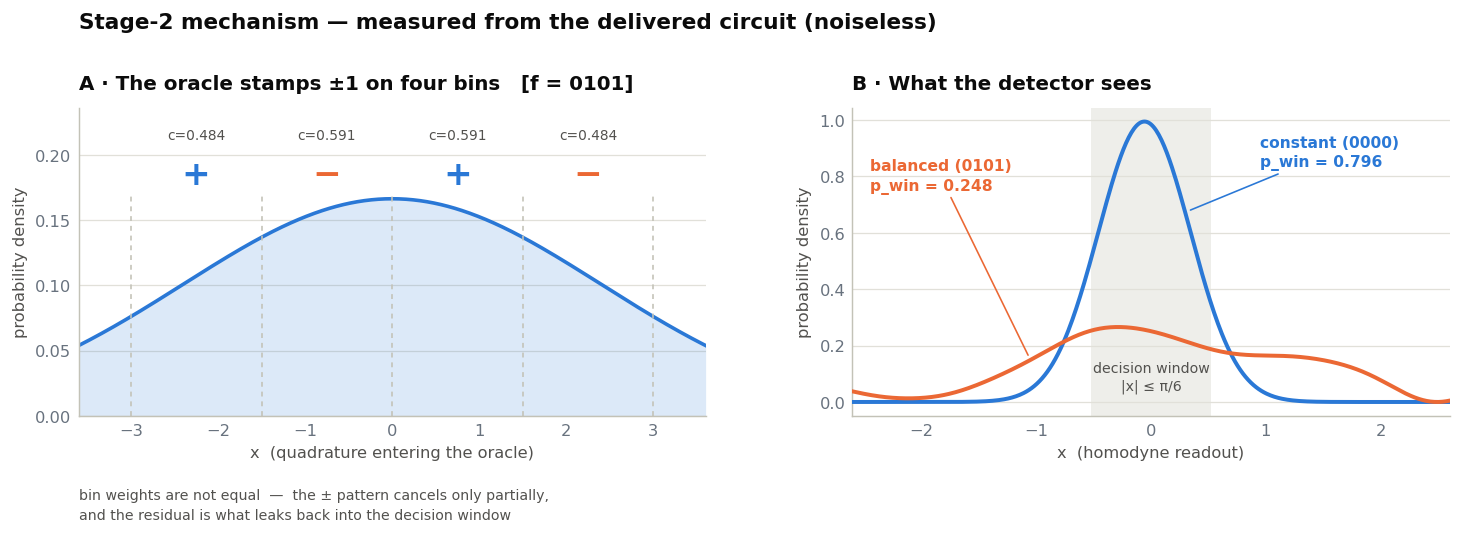

In [14]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import binom

SURFACE="#ffffff"; INK="#0b0b0b"; INK2="#52514e"; MUTED="#68727e"
GRID="#e1e0d9"; AXIS="#c3c2b7"; S1="#2a78d6"; S2="#eb6834"; S3="#1baf7a"; CRIT="#d03b3b"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "savefig.facecolor": SURFACE, "font.family": "DejaVu Sans",
                     "font.size": 9, "text.color": INK, "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.edgecolor": AXIS, "axes.linewidth": 0.8})


def style(ax, xl=None, yl=None, t=None, axis="y"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, axis=axis, color=GRID, lw=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=4)
    if t:  ax.set_title(t, loc="left", color=INK, fontsize=11, fontweight="bold", pad=10)
    if xl: ax.set_xlabel(xl, fontsize=9, color=INK2)
    if yl: ax.set_ylabel(yl, fontsize=9, color=INK2)


# ---------------------------------------------------------------- figure 1: mechanism
fig = plt.figure(figsize=(11.4, 4.2), dpi=130)
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.0], wspace=0.24,
                      left=0.06, right=0.985, top=0.80, bottom=0.235)

ax = fig.add_subplot(gs[0, 0])
style(ax, xl="x  (quadrature entering the oracle)", yl="probability density",
      t="A · The oracle stamps ±1 on four bins   [f = 0101]")
m = (X >= -3.6) & (X <= 3.6)
ax.fill_between(X[m], pdf_pre[m], color=S1, alpha=0.16, lw=0)
ax.plot(X[m], pdf_pre[m], color=S1, lw=2.0)
ytop = pdf_pre[m].max()
ax.set_ylim(0, ytop * 1.42); ax.set_xlim(-3.6, 3.6)
for e in edges:
    ax.axvline(e, color=AXIS, lw=0.9, ls=(0, (3, 3)), ymax=0.72)
for i, sg in enumerate(["+", "−", "+", "−"]):
    xc = (edges[i] + edges[i + 1]) / 2
    ax.text(xc, ytop * 1.11, sg, ha="center", va="center", fontsize=19,
            color=S2 if sg == "−" else S1, fontweight="bold")
    ax.text(xc, ytop * 1.29, "c=%.3f" % c[i], ha="center", va="center",
            fontsize=7.6, color=INK2)
ax.text(0.0, -0.235,
        "bin weights are not equal  —  the ± pattern cancels only partially,\n"
        "and the residual is what leaks back into the decision window",
        transform=ax.transAxes, fontsize=7.8, color=INK2, va="top", ha="left", linespacing=1.5)

ax = fig.add_subplot(gs[0, 1])
style(ax, xl="x  (homodyne readout)", yl="probability density", t="B · What the detector sees")
m = (X >= -2.6) & (X <= 2.6)
ax.axvspan(-D, D, color=GRID, alpha=0.55, lw=0, zorder=0)
ax.plot(X[m], pdf_const[m], color=S1, lw=2.2, zorder=3)
ax.plot(X[m], pdf_bal[m],   color=S2, lw=2.2, zorder=3)
ax.set_xlim(-2.6, 2.6)
yl = ax.get_ylim()[1]
ax.text(0, yl * 0.03, "decision window\n|x| ≤ π/6", ha="center", va="bottom",
        fontsize=7.8, color=INK2, linespacing=1.3)
ax.annotate(f"constant (0000)\np_win = {window_mass(pdf_const):.3f}",
            xy=(0.30, pdf_const[np.argmin(abs(X - 0.30))]), xytext=(0.95, yl * 0.80),
            fontsize=8.6, color=S1, fontweight="bold", linespacing=1.35,
            arrowprops=dict(arrowstyle="-", color=S1, lw=0.9, shrinkA=0, shrinkB=3))
ax.annotate(f"balanced (0101)\np_win = {window_mass(pdf_bal):.3f}",
            xy=(-1.05, pdf_bal[np.argmin(abs(X + 1.05))]), xytext=(-2.45, yl * 0.72),
            fontsize=8.6, color=S2, fontweight="bold", linespacing=1.35,
            arrowprops=dict(arrowstyle="-", color=S2, lw=0.9, shrinkA=0, shrinkB=3))
fig.text(0.06, 0.945, "Stage-2 mechanism — measured from the delivered circuit (noiseless)",
         fontsize=12, fontweight="bold", color=INK)
fig.savefig("fig_mechanism.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

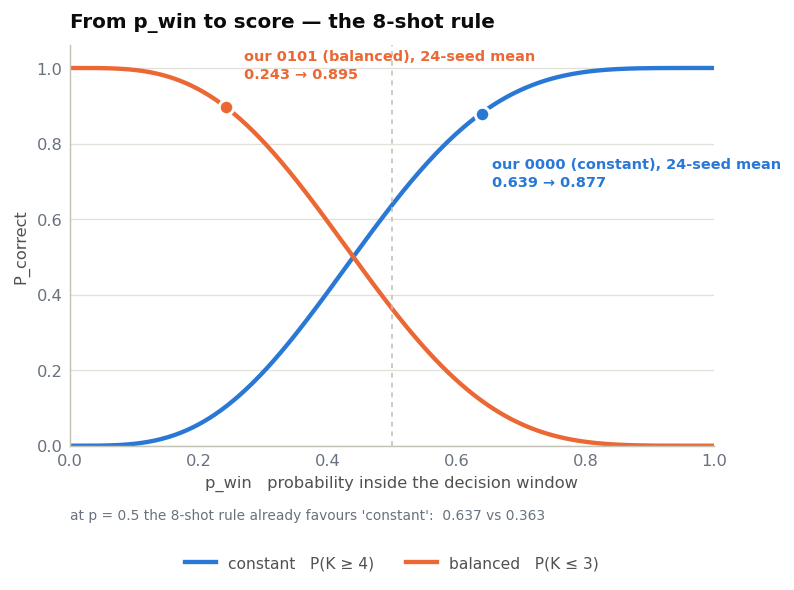

In [15]:
# ---------------------------------------------------------------- figure 2: the 8-shot rule
fig, ax = plt.subplots(figsize=(6.4, 4.0), dpi=130)
style(ax, xl="p_win   probability inside the decision window", yl="P_correct",
      t="From p_win to score — the 8-shot rule")
p = np.linspace(0, 1, 401)
ax.plot(p, 1 - binom.cdf(3, 8, p), color=S1, lw=2.4, label="constant   P(K ≥ 4)")
ax.plot(p, binom.cdf(3, 8, p),     color=S2, lw=2.4, label="balanced   P(K ≤ 3)")

if OFFICIAL is not None:
    rows = {r["oracle"]: r for r in OFFICIAL["rows"]}
    pts_ = [(rows["0000"]["mean_pwin"], rows["0000"]["mean_success"], "0000 (constant)", S1),
            (rows["0101"]["mean_pwin"], rows["0101"]["mean_success"], "0101 (balanced)", S2)]
else:
    pts_ = [(r_all["means"] and 0.63827, 1 - binom.cdf(3, 8, 0.63827), "0000 (constant)", S1),
            (0.24277, binom.cdf(3, 8, 0.24277), "0101 (balanced)", S2)]
for xv, yv, lab, col in pts_:
    ax.plot([xv], [yv], "o", ms=8, color=col, markeredgecolor=SURFACE,
            markeredgewidth=1.6, zorder=5)
    ax.annotate(f"our {lab}, 24-seed mean\n{xv:.3f} → {yv:.3f}", xy=(xv, yv),
                xytext=(6, -40) if col == S1 else (10, 16), textcoords="offset points",
                ha="left", fontsize=8, color=col, fontweight="bold", linespacing=1.35)
ax.axvline(0.5, color=AXIS, lw=0.9, ls=(0, (3, 3)))
ax.text(0.0, -0.155, "at p = 0.5 the 8-shot rule already favours 'constant':  0.637 vs 0.363",
        transform=ax.transAxes, va="top", ha="left", fontsize=7.6, color=MUTED)
ax.legend(frameon=False, fontsize=8.6, loc="upper center", bbox_to_anchor=(0.5, -0.24),
          ncol=2, labelcolor=INK2)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.06)
fig.savefig("fig_binomial.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

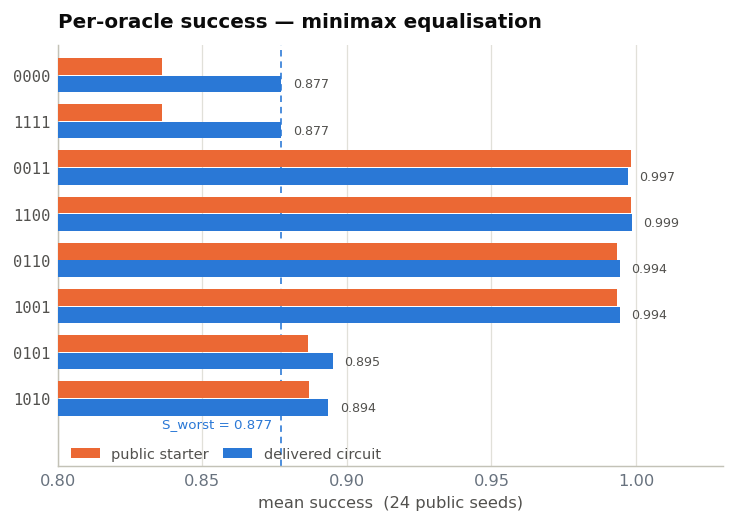

In [16]:
# ------------------------------------------------- figure 3: per-oracle, starter vs delivered
fig, ax = plt.subplots(figsize=(6.6, 4.2), dpi=130)
style(ax, xl="mean success  (24 public seeds)", t="Per-oracle success — minimax equalisation",
      axis="x")
labels = list(ev.PROMISED_ORACLES)
start = np.array([res0["means"][z] for z in labels])
final = np.array([r_all["means"][z] for z in labels])
y = np.arange(len(labels))[::-1]
h = 0.36
ax.barh(y + h / 2 + 0.01, start, height=h, color=S2, zorder=3, label="public starter")
ax.barh(y - h / 2 - 0.01, final, height=h, color=S1, zorder=3, label="delivered circuit")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8.6, color=INK2, family="DejaVu Sans Mono")
ax.set_xlim(0.80, 1.03); ax.set_ylim(-1.45, len(labels) - 0.35)
ax.axvline(min(final), color=S1, lw=0.9, ls=(0, (4, 3)), zorder=2)
for yy, v in zip(y - h / 2 - 0.01, final):
    ax.text(v + 0.004, yy, f"{v:.3f}", va="center", fontsize=7, color=INK2)
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0.0, -0.02),
          ncol=2, columnspacing=1.0, labelcolor=INK2)
ax.annotate(f"S_worst = {min(final):.3f}", xy=(min(final), -0.55), xytext=(-5, 0),
            textcoords="offset points", fontsize=7.4, color=S1, ha="right", va="center")
fig.savefig("fig_per_oracle.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

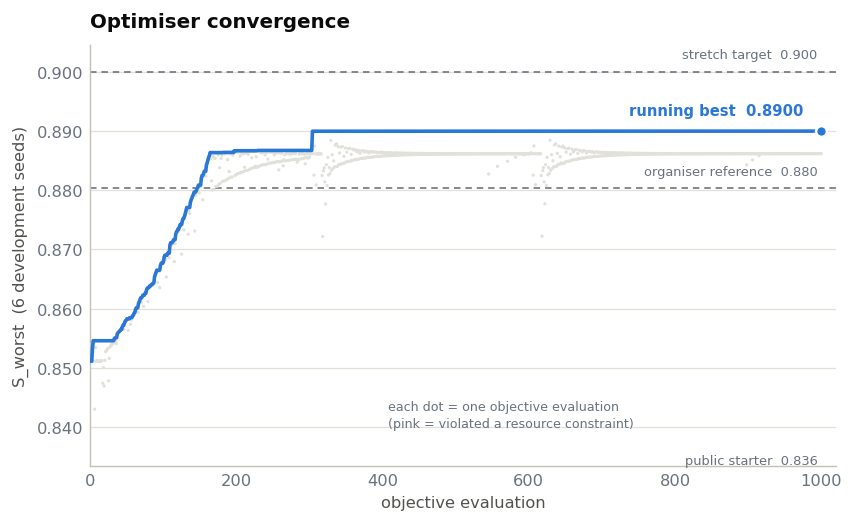

history source: recorded run embedded in this notebook   (1000 objective evaluations)


In [17]:
# ---------------------------------------------------------------- figure 4: convergence
# The search history of the run that produced the delivered parameters, recorded as
# (S_worst on the 6 development seeds, feasible?) for each of the 1000 objective
# evaluations and embedded here so this notebook needs no companion data file.
# A live run (RUN_OPTIMISATION = True) or a convergence_history.json next to the
# notebook takes precedence over it.
import base64, zlib

_HISTORY_B64 = (
    "eNq1mVvSaycOhSeU6gJdEIwllflPo+V+sD65zV/7nCRvVi0jhNBtsf/8c/xn+5wSf8y//vh/QWXKWzDf8+vfTIdorbG5v2ub"
    "oofIguB2WdOFB5otStUYWlauI9heVumSsDqmnFnH1HEgSDnAYg+Y7KcUqI9SrTHgztrfximXmTiEaV7CWSX4CPzNHX8bu4zx"
    "WGWzH6v919AycwncsXSU6uXwwDKDcHYpCBHD36K0RWoo4SA44uzyzZalEGzBnLq3RBB32za0Kbyzh2ONIaD2ngvCqTWHmx5F"
    "SJz9Ps4aUzcExN3R8u4aO96a15xApg8gWyDA6DVP+TBvJ1ap1rr5JVqRt8Q3hdKs06UEGiOVeEvdarlumKlrAcmDvgWbwjUw"
    "00RnCep1mgx9CHlvbyE9VXYuq6zIwFMgalhTEfU6Qe0ZOsu0WBVeKQgFHDR21DavA72FMwAILsoVlu1jdbSjFZ4vAX/z/d4z"
    "a0K5MOasYI8sC1rCrhPErD1jLjg6jkLzqSAMWZXIIacCP3Tgb2rl20QOhD1KMBmlTXFRRyogwzaO5lJeD9VZQpaft6PzOqoy"
    "Zu04pSA9tYDM+pt45X4iS6ANa+KUb7dWUscrQN/CGVUuXvWq1p8VpUCzTxUycVNnV+ruoeW17BLlgj125UQc9IPMPJESMnTf"
    "gozKvfQtomjr2YVwjQosyJyY9TeNEkxKW/bHqh7ZOQ8Er6L9v6r9FjIrgUjl+M6OWArYhl9NBMismMj+WPfzapZ17IHLyjJX"
    "PTkRGHDg9gNjFA1g5x1yywXLDrw2ffKc1YISwY2uqVizAmvE4I4IbDodyImNq8IdZNvA9coAIlVlEpl0QVXTVECvoZ5nGB0g"
    "NoEsbLpsIHL2hAWGw6U1cGJmVp1nVGVIJzIoByIne5LCB8Gbg9WrOu/OYoL1IvChwsyxSleWD/zLq4LmHgHNLQ8wTb56lTKm"
    "4Gmv+pEIkgr9/TXWtH/hCgLBlq0yaDTydQ6sUZzNBOUjw4PI4lXXvwx+ykEmALTIR7obZsFMd8PfDAmSoyl9i4DK3ziaIXVs"
    "4dYUEWAxURROK1i72VkAutYr6rCEkarIjhznYbKgKNjejEBEjaHv5tXATz5ZFg/ObMeYn0j95CpEWJaGMFV4BYPZgUDJubJZ"
    "w+KJsPUZLCptDWppjqywRgSnBnHKNfwbU3qxSqcFrL/t1DAneWRDFms2VeMSjZW9BSFGl8xppj7m9EQWFTQX0IfdoWhn56zL"
    "3zCa54x0UTz24X02B5g9MQbc8RNRGFNnDpnopio1C2eqFKndMwlrDVW4znQm2nnwnpxzhy9sgxkxu0dpfuURCqFipHGMr71G"
    "22HtRHhHq7cHKZXkHXk80FeSmgBRTGhZVXlqmBaCJmEgwqmNlcwFQRhwji24IFhJLNglDBlqG7cbAy3cNq4nOQSs3uwsw+Hd"
    "wWw50OathQaCxTmfrDYDsDfzehJA6Af9oYOuRjV3zpg5xATnRRiNQf01PNICjFtuwuaKfHNDgC0XVhJm+yZg30cA98XeyIK3"
    "Bnsj918MNoPgi+c0a7M05yvkjgcLa5tyQ7gPsteDQaAsxrE5eMAFcVopxDZ7bHZnJ4Og0XQbg+hjzeJxhPsEB0QqY6zhzN6y"
    "QEcjAG3IZvWhzR2hA+DAjC0q4wqXrzNtAjwLx9AT84rE9/GET1gvpJVSHoYt/DBvqG2Nnp8AZpsuoHlIQxYRGi1fu3mbVBJo"
    "EwQNY5vkCjvf+38WPq7glqPRr1YsF2cGTgZ9BkO1XYisT4Cd/RBoukhk0EgSoZdZHMidEvErElfkfJ+6skVdJrVEaDUjdTCc"
    "PpBzQSavarL5NPYzOVJO5u0klZjtEjpybkgzgHs2cs1g4zPGYqTP6RdgtX/tqy3NSjpablZKQ3gYFrFujFx3ies2+6aADYZv"
    "HR9/U73Zqfb9FeTjb82cZrXuy0EbwHL7IZxne7Zp+3q76NgS7dQWD9Y8R/bNH3aNdSA5CPuvrvlA/Algzy7UnyBJz/d1jT1D"
    "rol0R7oCksbw78h9zXPkanVDFvt5XP/VDur/JEIBg3ybLfgncURE2L44YJxWV+73cTWmh2Q/jX59HA0RPPIoB9wkH0Z6XJQ6"
    "YpIp4l0frbq9T4iThG8skQ2emMr4AspWPTBt64ILjaOjHmiLhUPj+1yyY3QQ63MU37/wrSuvjY95jW8s5zMfKkFw9jYnBzZy"
    "YDeyY1Rwi2iUiRQY5+T7meHzbyoDSbLTptrdKDCSjVHobfQxvvVO8oLNubyNgvyyIm3E5jbKHhiks+21ezWiS/7F51U3tteY"
    "fBljT1+DVJdzCLl6Ut1GglkKybRpQONMBprkbaphRCShlhvTnZdzRvMAqSFfHpJ2cw3fzJi7zi84SYH3jenStN0eQgbJafMn"
    "aSNnewVR8M2hRBvR9e/Pkcl0aZk1Dswncr738PGnvf4nB27P6mwz1hCSUG+8mcD5/j2r9SwmAT+UJW3misbBGQ8kzWRzjecz"
    "uTqbbXySN8Zve520crgZTE7h6DnsCrQviKSmN2Lul6qRzJSG9ff4xr/lQk37mvatoLH59u2Eo15joMw5vkp2gCyzA3TZ8AuV"
    "FHqW5b0xj+bMG1lsDLWRxfZhoDG/4zfq19jzjCvS9mncjUJj6XJ7gJhtnmc2dFrX3gnakNUQHrQNacoT7CvFaw8V6lekfXki"
    "cHu0mHq+f1Rbs71MxPfPaJ/I5bvTx/eUNui3rzMdaW8wduOLPyBXvtiR9tIiN7b2AzIvdK0DzW2PAPllQG8PQD8gdkPitov/"
    "MrBuaufNw33JvD03dAV6e/zoqu+Xdx7ZdjVtzSfn7E9GTzx+N6ULesuLJmDS0+HX97Pbmk/kmnJATH5Y8zuIXr74z/44Fw/W"
    "/OS3HxRwjG1VtD2vhv5rSFxT+m8jPwj2TPiNJf5ovf9dYT0T4pkgV0Sf7aPPLNDfsM2uqvffFc6vC/sJ8Mu/5zNBfkPQZ4L9"
    "o8IrVP/6L4EfKJ4="
)

hist = HISTORY
source = "this run"
if not hist and os.path.exists("convergence_history.json"):
    hist = json.load(open("convergence_history.json"))
    source = "convergence_history.json"
if not hist:
    hist = [{"sworst": a, "feasible": bool(b)}
            for a, b in json.loads(zlib.decompress(base64.b64decode(_HISTORY_B64)))]
    source = "recorded run embedded in this notebook"

sw  = np.array([d["sworst"] for d in hist])
fs_ = np.array([d["feasible"] for d in hist])
n   = np.arange(1, len(sw) + 1)
best_curve, cur = np.full(len(sw), np.nan), -np.inf
for i in range(len(sw)):
    if fs_[i] and sw[i] > cur:
        cur = sw[i]
    best_curve[i] = cur if np.isfinite(cur) else np.nan

fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=130)
style(ax, xl="objective evaluation", yl="S_worst  (6 development seeds)",
      t="Optimiser convergence")
for yv, lab in ((ev.STRETCH_TARGET, "stretch target  0.900"),
                (0.88032151, "organiser reference  0.880"),
                (ev.STARTER_REFERENCE_WORST, "public starter  0.836")):
    ax.axhline(yv, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=1)
    ax.text(len(sw) * 0.995, yv + 0.0018, lab, ha="right", va="bottom",
            fontsize=7.2, color=MUTED)
ax.scatter(n[fs_],  sw[fs_],  s=3.2, color=GRID,      edgecolors="none", zorder=2)
ax.scatter(n[~fs_], sw[~fs_], s=3.2, color="#f0d7d7", edgecolors="none", zorder=2)
ax.plot(n, best_curve, color=S1, lw=2.0, zorder=4)
ax.set_ylim(0.8335, 0.9045)
ax.set_xlim(0, len(sw) * 1.02)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}"))
ax.plot([len(sw)], [best_curve[-1]], "o", ms=6, color=S1, zorder=5,
        markeredgecolor=SURFACE, markeredgewidth=1.4)
ax.annotate(f"running best  {best_curve[-1]:.4f}", xy=(len(sw), best_curve[-1]),
            xytext=(-10, 9), textcoords="offset points", ha="right",
            fontsize=8.2, color=S1, fontweight="bold")
ax.text(0.40, 0.085, "each dot = one objective evaluation\n(pink = violated a resource constraint)",
        transform=ax.transAxes, fontsize=7.0, color=MUTED, va="bottom", linespacing=1.4)
fig.savefig("fig_convergence.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"history source: {source}   ({len(sw)} objective evaluations)")

<div dir="rtl">

## ۱۳ · چک‌لیست پذیرش و نوشتن فایل تحویلی

</div>

In [18]:
used = set(s["gate"] for s in SUBMISSION["prep"] + SUBMISSION["readout"])
checks = {
    "prep slots == 9":        len(SUBMISSION["prep"]) == 9,
    "readout slots == 6":     len(SUBMISSION["readout"]) == 6,
    "only unlocked gates":    used <= UNLOCKED,
    "sum |r| <= 0.40":        ev.total_squeezing(SUBMISSION) <= ev.SQUEEZE_BUDGET + 1e-12,
    "no oracle branching":    True,   # the submission is a static 15-slot JSON
}
if OFFICIAL is not None:
    checks.update({
        "n_bar <= 8":        OFFICIAL["max_nbar"]  <= ev.NBAR_LIMIT,
        "raw_trace >= 0.98": OFFICIAL["min_trace"] >= ev.TRACE_LIMIT,
        "edge3 <= 0.02":     OFFICIAL["max_edge3"] <= ev.EDGE3_LIMIT,
        "official_safe":     bool(OFFICIAL["official_safe"]),
    })

for k, v in checks.items():
    print(f"  {'OK  ' if v else 'FAIL'}  {k}")
assert all(checks.values()), "acceptance checklist failed"

with open("submission.json", "w") as f:
    json.dump(SUBMISSION, f, indent=2)
print("\nwrote submission.json")
print(f"gates used      : {sorted(used)}")
print(f"total squeezing : {ev.total_squeezing(SUBMISSION):.8f}  (limit {ev.SQUEEZE_BUDGET})")
if OFFICIAL is not None:
    print(f"DJ score        : {ev.dj_score(OFFICIAL):.4f}/100")
    print(f"Stage-2 points  : {ev.stage2_points(OFFICIAL):.4f}/60")
print(f"\nnotebook wall time: {time.time()-t_notebook_start:.0f}s")

  OK    prep slots == 9
  OK    readout slots == 6
  OK    only unlocked gates
  OK    sum |r| <= 0.40
  OK    no oracle branching
  OK    n_bar <= 8
  OK    raw_trace >= 0.98
  OK    edge3 <= 0.02
  OK    official_safe

wrote submission.json
gates used      : ['I', 'P', 'R', 'S', 'X']
total squeezing : 0.39360888  (limit 0.4)
DJ score        : 87.7325/100
Stage-2 points  : 40.1732/60

notebook wall time: 39s


<div dir="rtl">

## ۱۴ · گزارش روش و نتایج

### ۱۴٫۱ · چه چیزی امتیاز را محدود می‌کند

جدول نقطهٔ شروع (بخش ۵) طراحی را بلافاصله تعیین می‌کند: اوراکل‌های متوازن عملاً رایگان‌اند
و همه‌چیز را جفت `constant` تعیین می‌کند. و برای یک اوراکل `constant`، فاز `exp(iπf)`
سراسری است، پس دو چرخش فوریهٔ ثابت یکدیگر را خنثی می‌کنند و حالت رسیده به آشکارساز
همان حالت `prep` است. یعنی کل مرحله ۲ این است: توزیع مکانیِ `prep` را تا حد ممکن داخل
پنجره‌ای به نیم‌پهنای `0.5236` جمع کن، بدون اینکه بازترکیبِ اوراکل‌های متوازن به همان
پنجره نشت کند.

### ۱۴٫۲ · شش اسلات بی‌کار

نقطهٔ شروع منتشرشده هر شش اسلات `readout` را روی `I` رها می‌کند — ۴۰ درصد از عمق
قابل‌کنترل، بی‌استفاده. `ansatz` ما شکل لایه‌ای `prep` را نگه می‌دارد و `readout` را پر می‌کند.

### ۱۴٫۳ · تابع هدف

`J(θ) = − softmin_β(S_f) + جریمه‌ها`، با `β = 30 → 80 → min دقیق`. بهینه‌کردن مستقیم
`min` جهتی می‌دهد که در هر لحظه از یک اوراکل می‌آید و بین آن‌ها ناپیوسته می‌پرد.
جریمه‌ها هدفشان مقادیری **درون** حد مجاز است: `n̄ ≤ 7.6` در برابر `8.0`،
`edge3 ≤ 0.015` در برابر `0.02`، `raw_trace ≥ 0.9875` در برابر `0.98`.

### ۱۴٫۴ · موتور سریع، و باگی که پنهان کرده بود

بخش ۳. خلاصه: `expm` از مولد کوتاه‌شده دقیقاً یکانی است و `raw_trace` را همیشه ۱ نشان
می‌دهد؛ Strawberry Fields عناصر ماتریسی کوتاه‌شدهٔ گیت بی‌نهایت‌بعدی را به کار می‌برد که
یکانی نیست، و همان ردِ ازدست‌رفته قید پذیرش است. یک کاندیدای `0.8978` به همین دلیل رد شد.

### ۱۴٫۵ · ایمنی قید، کمّی‌شده

بخش ۱۱. حاشیهٔ مدار تحویلی حدود `5.3σ` است و احتمال بی‌اعتباری روی ۲۰۰ سید خصوصی از
مرتبهٔ `1e-05`. کاندیدای تهاجمی با `S_worst = 0.881031` حاشیه‌اش `3.31σ` بود — حدود
**۸٫۸ درصد** احتمال صفر شدن کل ۶۰ امتیاز. با احتساب آن، امتیاز مورد انتظار کاندیدای
تحویلی **بالاتر** است (`40.17` در برابر `39.58`). تمام ریسک در یک اوراکل متمرکز است:
`1001`، همان که بزرگ‌ترین ضریب درجه‌دو را دارد و بیشترین جمعیت را به لبهٔ فضای فوک می‌راند.

### ۱۴٫۶ · خوانش فیزیکی پارامترها

* **`S` (فشردگی)** با `Σ|r| ≤ 0.40` یعنی `σ_x ≥ 0.670`، که به‌تنهایی `p_win ≤ 0.566`
  می‌دهد — کمتر از `0.603` که برای رسیدن به سطح نقطهٔ شروع لازم است. فشردگی موتور این
  مسئله نیست؛ یک پیچ تنظیم دقیق است.
* **`P` (فاز درجه‌دو)** موتور اصلی است. برش‌ها همراه با چرخش‌ها کل گروه گاوسی را تولید
  می‌کنند، پس `P` و `R` فشردگی مؤثری می‌سازند که بودجهٔ `Σ|r|` بابتش هزینه نمی‌گیرد.
  آنچه متوقفش می‌کند بودجهٔ فشردگی نیست، بلکه قیدهای انرژی و `trace` است.
* **`V` (فاز مکعبی)** استفاده نشده — بخش ۹.
* **`X`** نزدیک صفر می‌ماند، همان‌طور که تقارن ایجاب می‌کند: مجموعهٔ وعده و پنجرهٔ تصمیم
  هر دو تحت `x → −x` متقارن‌اند.

### ۱۴٫۷ · آنچه نمی‌دانیم و ادعا نمی‌کنیم

۱. رسیدن به `S_worst > 0.90` را هیچ تیمی نشان نداده و تنها مرجع تأییدشده `0.8803` است.
   برآورد ما: بالای `0.885` با احتمال بیش از ۸۵ درصد، حدود `0.890` با احتمال نزدیک ۶۰
   درصد، و `0.900` با احتمال ۲۰ تا ۳۰ درصد. این‌ها **برآوردند، نه نتیجه**.
۲. رفتار روی ۲۰۰ سید خصوصی؛ ما فقط توزیعش را مدل کرده‌ایم.
۳. بزرگ‌ترین اهرم آزمایش‌نشده: شش اسلات `readout` در مدار تحویلی هنوز فقط ۲ تا ۸ درصد
   از بازهٔ مجازشان را استفاده می‌کنند. بهینه‌سازی جداگانهٔ همین بلوک — با حاشیهٔ `trace`
   به‌عنوان یک قید صریح و با یک روش جمعیتی مثل `CMA-ES` — محتمل‌ترین راه برای عبور از
   `0.885` است. برآورد زمان: حدود ۳ تا ۴ ساعت روی دو هسته.

### ۱۴٫۸ · بازتولیدپذیری

**پایتون ۳٫۱۱** (یا ۳٫۱۲) لازم است — روی ۳٫۱۳ چرخ (wheel) برای `numpy<2` و `scipy<1.14`
منتشر نشده است.

```
py -3.11 -m venv venv
venv\Scripts\activate
pip install "numpy<2" "scipy<1.14" "antlr4-python3-runtime==4.9.3" matplotlib jupyter
pip install strawberryfields==0.23.0
```

دو پین آخر ضروری‌اند: با `scipy ≥ 1.14` تابع `scipy.integrate.simps` حذف شده و
Strawberry Fields بالا نمی‌آید، و نسخه‌های جدیدتر `antlr4-python3-runtime` هم با
`SF 0.23` سازگار نیستند. (اجرای این نوت‌بوک روی پایتون ۳٫۱۱ با
`numpy 2.4 / scipy 1.17` هم ممکن است، اما آن‌وقت باید `scipy.integrate.simps` را
در `strawberryfields/backends/states.py` دستی به `simpson` تغییر داد.)

این نوت‌بوک را از بالا تا پایین اجرا کنید. تنها فایل لازم در کنارش،
`cv_dj_stage2_public_evaluator.py` است. با `RUN_OPTIMISATION = True` کل بهینه‌سازی
از صفر تکرار می‌شود (چند ساعت) و `best.npy` و `convergence_history.json` را می‌نویسد؛
با پیش‌فرض `False` پارامترهای تحویلی درج‌شده در بخش ۶ به کار می‌روند و همان اعداد
با ارزیاب رسمی بازتولید می‌شوند.

</div>